# Salvo - Knowledge Sharing Session 1 (2026)
## Hands-On Regression Analysis: Simple, Multiple, Preprocessing & Evaluation

<a href="https://colab.research.google.com/github/Ranker-AdhipKumar/Salvo_Knowledge_sharaing_session_1_2026/blob/main/notebooks/01_regression_analysis_handson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Conducted by:** Adhip Kumar & C. G. Rajiv Subramaniam  
**Organized by:** Salvo - The Official AI Club of SASTRA

---

### Notebook Overview
This notebook contains the complete, interactive walkthrough from **Salvo Knowledge Sharing Session 1 (2026)**. It covers practical regression workflows:
1. **Environment Setup & Dependencies**
2. **Simple Linear Regression** (Dataset creation, Ordinary Least Squares fitting)
3. **Model Inference** (Predicting outcomes on unseen data)
4. **Residual Analysis & Sum of Squared Errors (SSE)**
5. **Model Evaluation Metrics** ($R^2$, MAE, MSE, RMSE)
6. **Multiple Linear Regression** (Multivariate modeling)
7. **Categorical Feature Encoding** (One-Hot Encoding via `pd.get_dummies`)
8. **Feature Scaling** (Z-Score Standardization via `StandardScaler`)
9. **Model Validation & Visualization** (Train/Test Split & Plotting the regression fit)

## 1. Environment Setup & Package Installation
Install required dependencies: `pandas`, `scikit-learn`, `matplotlib`, and `numpy`.

In [ ]:
!pip install pandas scikit-learn matplotlib

## 2. Simple Linear Regression: Data Preparation
Define a baseline dataset tracking the relationship between study hours and exam scores.

In [ ]:
# Input data loading
import pandas as pd

data = pd.DataFrame({
    "hours": [1, 2, 3, 4, 5],
    "score": [48, 60, 62, 74, 76]
})

X = data[["hours"]]   # Input feature matrix
y = data["score"]     # Target response vector

print(data)


   hours  score
0      1     48
1      2     60
2      3     62
3      4     74
4      5     76


## 3. Model Training & Parameter Interpretation
Fit an Ordinary Least Squares (OLS) Linear Regression model to learn the optimal slope ($m$) and intercept ($c$):
$$\hat{y} = mx + c$$

In [ ]:
# Fit linear regression model
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)

print("Slope (coef_):", model.coef_[0])
print("Intercept (intercept_):", model.intercept_)


Slope: 7.0
Intercept: 43.0


## 4. Inference: Making Predictions on Unseen Data
Predict the expected exam score for a new student studying 6 hours.

In [ ]:
# Predict for a new student studying 6 hours
new_student = pd.DataFrame({"hours": [6]})
predicted_score = model.predict(new_student)

print("Predicted score for 6 hours:", predicted_score[0])


Predicted score: 85.0


## 5. Residual Analysis: Sum of Squared Errors (SSE)
Compute residuals ($e_i = y_i - \hat{y}_i$) and the Sum of Squared Errors:
$$\text{SSE} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

In [ ]:
# Calculate Sum of Squared Errors (SSE)
import numpy as np

predictions = model.predict(X)
errors = y - predictions
squared_errors = errors ** 2
SSE = np.sum(squared_errors)

print("Actual scores:  ", list(y))
print("Predictions:    ", list(predictions))
print("Errors:         ", list(errors))
print("Squared errors: ", list(squared_errors))
print("SSE:            ", SSE)


Actual scores: [48, 60, 62, 74, 76]
Predictions: [50. 57. 64. 71. 78.]
Errors: [-2.0, 3.0, -2.0, 3.0, -2.0]
Squared errors: [4.0, 9.0, 4.0, 9.0, 4.0]
SSE: 30.0


## 6. Comprehensive Model Evaluation Metrics
Evaluate performance using standard regression metrics:
- **MAE (Mean Absolute Error):** $\frac{1}{n} \sum |y - \hat{y}|$
- **MSE (Mean Squared Error):** $\frac{1}{n} \sum (y - \hat{y})^2$
- **RMSE (Root Mean Squared Error):** $\sqrt{\text{MSE}}$
- **$R^2$ (Coefficient of Determination):** Proportion of variance explained by the model

In [ ]:
# Model evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y, predictions)
mse = mean_squared_error(y, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y, predictions)

print("MAE:      ", mae)
print("MSE:      ", mse)
print("RMSE:     ", rmse)
print("R-squared:", r2)


MAE: 2.4
MSE: 6.0
RMSE: 2.449489742783178
R-squared: 0.9423076923076923


## 7. Multiple Linear Regression (Multivariate Features)
Model target outcome with multiple factors (`hours`, `sleep`, `attendance`):
$$\hat{y} = \beta_0 + \beta_1 x_{\text{hours}} + \beta_2 x_{\text{sleep}} + \beta_3 x_{\text{attendance}}$$

In [ ]:
# Multiple Linear Regression with multiple input features
import pandas as pd
from sklearn.linear_model import LinearRegression

data_multi = pd.DataFrame({
    "hours":      [1, 2, 3, 4, 5, 6],
    "sleep":      [5, 6, 7, 6, 8, 7],
    "attendance": [60, 65, 70, 75, 85, 90],
    "score":      [45, 50, 60, 65, 78, 85]
})

X_multi = data_multi[["hours", "sleep", "attendance"]]
y_multi = data_multi["score"]

model_multi = LinearRegression()
model_multi.fit(X_multi, y_multi)

print("Intercept:   ", model_multi.intercept_)
print("Coefficients:", model_multi.coef_)


Intercept: -21.956521739130473
Coefficients: [1.69565217 0.47826087 1.03478261]


### Predicting with the Multiple Regression Model
Estimate the exam score for a student with 5 hours of study, 7 hours of sleep, and 80% attendance:

In [ ]:
# Prediction using Multiple Regression model
student = pd.DataFrame({
    "hours": [5],
    "sleep": [7],
    "attendance": [80]
})

print("Predicted score:", model_multi.predict(student)[0])


Predicted score: 72.65217391304347


## 8. Categorical Feature Encoding (One-Hot Encoding)
Convert non-numeric categorical attributes (`study_mode`: "Online", "Offline") into numerical binary indicator columns using `pd.get_dummies` with `drop_first=True` to avoid multicollinearity.

In [ ]:
# Categorical Encoding using One-Hot Encoding
import pandas as pd
from sklearn.linear_model import LinearRegression

data_cat = pd.DataFrame({
    "hours": [2, 3, 4, 5, 2, 4],
    "study_mode": [
        "Online", "Online", "Online",
        "Online", "Offline", "Offline"
    ],
    "score": [55, 60, 70, 75, 52, 65]
})

# Convert categories into indicator columns
X_cat = pd.get_dummies(
    data_cat[["hours", "study_mode"]],
    columns=["study_mode"],
    drop_first=True,
    dtype=int
)
y_cat = data_cat["score"]

model_cat = LinearRegression()
model_cat.fit(X_cat, y_cat)

print("Encoded features:")
print(X_cat)
print("\nLearned coefficients:", model_cat.coef_)


Encoded features:
   hours  study_mode_Online
0      2                  1
1      3                  1
2      4                  1
3      5                  1
4      2                  0
5      4                  0
Learned coefficients: [6.85714286 3.07142857]


## 9. Feature Scaling: Standardization
Features with drastically different scales (e.g. `hours` ~ [1-5] vs `income` ~ [100k-1M]) can bias optimization. We standardize features to mean $\mu=0$ and variance $\sigma^2=1$ using `StandardScaler`:
$$z = \frac{x - \mu}{\sigma}$$

In [ ]:
# Feature scaling via Z-score standardization
import pandas as pd
from sklearn.preprocessing import StandardScaler

X_unscaled = pd.DataFrame({
    "hours": [1, 2, 3, 4, 5],
    "attendance": [40, 55, 70, 85, 100],
    "income": [100000, 250000, 500000, 750000, 1000000]
})

scaler = StandardScaler()
X_scaled_arr = scaler.fit_transform(X_unscaled)

X_scaled = pd.DataFrame(
    X_scaled_arr,
    columns=X_unscaled.columns
)

print(X_scaled.round(2))


   hours  attendance  income
0  -1.41       -1.41   -1.29
1  -0.71       -0.71   -0.83
2   0.00        0.00   -0.06
3   0.71        0.71    0.70
4   1.41        1.41    1.47


## 10. Train/Test Split, Model Validation & Visualization
Split the dataset into training (80%) and testing (20%) partitions using `train_test_split` to rigorously test out-of-sample generalization.

In [ ]:
# Train-test split and evaluation on test holdout
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

X_hours = data[["hours"]]
y_score = data["score"]

X_train, X_test, y_train, y_test = train_test_split(
    X_hours, y_score, test_size=0.2, random_state=42
)

model_split = LinearRegression()
model_split.fit(X_train, y_train)

test_predictions = model_split.predict(X_test)
print("Test MAE:", mean_absolute_error(y_test, test_predictions))


Test MAE: 1.6052631578947398


### Visualizing Training Data, Test Holdout, and the Regression Line
Plot the training set (blue circles), testing set (orange squares), and the learned regression fit (red dashed line):

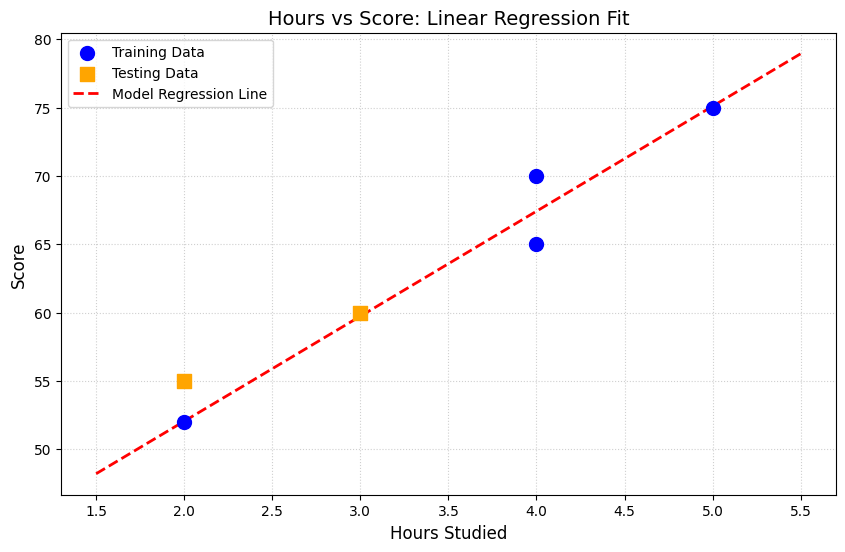

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Configure plot
plt.figure(figsize=(10, 6))

# Plot training data points
plt.scatter(X_train, y_train, color='blue', label='Training Data', s=100, zorder=3)

# Plot testing data points
plt.scatter(X_test, y_test, color='orange', label='Testing Data', s=100, marker='s', zorder=3)

# Generate points to plot the regression line
x_range = np.linspace(X_hours['hours'].min() - 0.5, X_hours['hours'].max() + 0.5, 100).reshape(-1, 1)
y_line = model_split.predict(pd.DataFrame(x_range, columns=['hours']))

# Plot the regression line
plt.plot(x_range, y_line, color='red', linestyle='--', linewidth=2, label='Model Regression Line')

# Graph styling
plt.title('Hours vs Score: Linear Regression Fit', fontsize=14, fontweight='bold')
plt.xlabel('Hours Studied', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()
